<a href="https://colab.research.google.com/github/NamithaDaney/ABC-Company-Assessment/blob/main/Autoencoder_Anomaly_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

There is one important distinction: the Autoencoder can automate many preprocessing actions, but it should not blindly execute every recommendation in the plan. Some actions require validation or human review.



The biggest challenge: different datasets
Suppose DataLens AI processes these datasets:
- cardhekho.xlsx — vehicle information
- sales.csv — sales transactions
- customer_data.xlsx — customer information
Each may require different cleaning operations. Your preprocessing engine can handle many of those differences dynamically.

But the existing trained Autoencoder cannot automatically work with all three datasets. It was trained using 26 vehicle-related columns, and its fitted preprocessor expects the corresponding feature schema.

In [14]:
from pathlib import Path
import pandas as pd

# DataLens AI reports directory
REPORT_DIR = Path(
    "/content/drive/MyDrive/ENTRI Folder/ASSIGNMENTS/Final Main Project/"
    "DataLens_AI/reports"
)

# Find all preprocessing plan CSV files
plan_files = sorted(
    REPORT_DIR.glob("*/ *_preprocessing_plan.csv".replace(" ", ""))
)

print("Preprocessing plans found:", len(plan_files))

for plan_file in plan_files:
    print(plan_file)

Preprocessing plans found: 1
/content/drive/MyDrive/ENTRI Folder/ASSIGNMENTS/Final Main Project/DataLens_AI/reports/cardhekho/cardhekho_preprocessing_plan.csv


In [15]:
# Find the dataset corresponding to the preprocessing plan
INPUT_DIR = REPORT_DIR.parent / "input"

if len(plan_files) == 1:
    plan_file = plan_files[0]
    dataset_name = plan_file.parent.name

    matching_datasets = [
        path for path in INPUT_DIR.iterdir()
        if path.is_file()
        and path.stem == dataset_name
        and path.suffix.lower() in {".csv", ".xlsx", ".xls"}
        and not path.name.startswith("~$")
    ]

    if len(matching_datasets) == 1:
        file_path = matching_datasets[0]

        print("Preprocessing plan:", plan_file.name)
        print("Dataset found:", file_path.name)
        print("Dataset path:", file_path)

    elif len(matching_datasets) == 0:
        raise FileNotFoundError(
            f"No dataset found for preprocessing plan: {plan_file.name}"
        )

    else:
        raise ValueError(
            f"Multiple datasets found for: {dataset_name}"
        )

elif len(plan_files) == 0:
    raise FileNotFoundError("No preprocessing plans were found.")

else:
    raise ValueError(
        "Multiple preprocessing plans found. Select the intended plan first."
    )

Preprocessing plan: cardhekho_preprocessing_plan.csv
Dataset found: cardhekho.xlsx
Dataset path: /content/drive/MyDrive/ENTRI Folder/ASSIGNMENTS/Final Main Project/DataLens_AI/input/cardhekho.xlsx


In [16]:
# Load the preprocessing plan corresponding to the selected dataset
preprocessing_plan = pd.read_csv(plan_file)

print("Preprocessing plan loaded successfully!")
print("Dataset:", dataset_name)
print("Plan path:", plan_file)
print("Plan shape:", preprocessing_plan.shape)

display(preprocessing_plan.head())

Preprocessing plan loaded successfully!
Dataset: cardhekho
Plan path: /content/drive/MyDrive/ENTRI Folder/ASSIGNMENTS/Final Main Project/DataLens_AI/reports/cardhekho/cardhekho_preprocessing_plan.csv
Plan shape: (37, 6)


,column,issue,affected_count,proposed_action,reason,status
0,priceActual,Missing values,6699,Review missing-value treatment,80.05% of values are missing. Choose a treatme...,Needs review
1,Wheel Size,Missing values,2983,Review missing-value treatment,35.64% of values are missing. Choose a treatme...,Needs review
2,RTO,Missing values,894,Review missing-value treatment,10.68% of values are missing. Choose a treatme...,Needs review
3,Mileage,Missing values,287,Review missing-value treatment,3.43% of values are missing. Choose a treatmen...,Needs review
4,Torque,Missing values,60,Review missing-value treatment,0.72% of values are missing. Choose a treatmen...,Needs review


In [17]:
# Summarize preprocessing recommendations
required_columns = {"proposed_action", "status"}
missing_columns = required_columns - set(preprocessing_plan.columns)

if missing_columns:
    raise KeyError(
        f"Preprocessing plan is missing columns: {sorted(missing_columns)}"
    )

print("Recommendations by proposed action:")
display(
    preprocessing_plan["proposed_action"]
    .value_counts()
    .rename_axis("proposed_action")
    .reset_index(name="count")
)

print("\nRecommendations by status:")
display(
    preprocessing_plan["status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="count")
)

Recommendations by proposed action:


,proposed_action,count
0,Review missing-value treatment,16
1,CONVERT_CANDIDATE,6
2,Inspect outlier values,3
3,REVIEW_DUPLICATE_COLUMNS,3
4,REVIEW_REQUIRED,2
5,NORMALIZE_AND_CONVERT,2
6,REMOVE_CANDIDATE,2
7,Review column before removal,1
8,REVIEW_CONSTANT_COLUMN,1
9,Review date standardization,1



Recommendations by status:


,status,count
0,Needs review,19
1,Validate conversion first,6
2,Review; do not delete automatically,3
3,Verify before removal,3
4,Validate parsing and units first,2
5,Manual review required,2
6,Safe candidate; verify before removal,2


In [18]:
# Summarize the recommendations in the selected preprocessing plan

print("Dataset:", dataset_name)
print("Total recommendations:", len(preprocessing_plan))

print("\nRecommendations by proposed action:")

display(
    preprocessing_plan["proposed_action"]
    .value_counts()
    .rename_axis("proposed_action")
    .reset_index(name="count")
)

print("\nFull preprocessing recommendations:")

display(
    preprocessing_plan[
        ["column", "issue", "proposed_action", "status"]
    ]
)

Dataset: cardhekho
Total recommendations: 37

Recommendations by proposed action:


,proposed_action,count
0,Review missing-value treatment,16
1,CONVERT_CANDIDATE,6
2,Inspect outlier values,3
3,REVIEW_DUPLICATE_COLUMNS,3
4,REVIEW_REQUIRED,2
5,NORMALIZE_AND_CONVERT,2
6,REMOVE_CANDIDATE,2
7,Review column before removal,1
8,REVIEW_CONSTANT_COLUMN,1
9,Review date standardization,1



Full preprocessing recommendations:


,column,issue,proposed_action,status
0,priceActual,Missing values,Review missing-value treatment,Needs review
1,Wheel Size,Missing values,Review missing-value treatment,Needs review
2,RTO,Missing values,Review missing-value treatment,Needs review
3,Mileage,Missing values,Review missing-value treatment,Needs review
4,Torque,Missing values,Review missing-value treatment,Needs review
5,Max Power,Missing values,Review missing-value treatment,Needs review
6,Registration Year,Missing values,Review missing-value treatment,Needs review
7,Ownership,Missing values,Review missing-value treatment,Needs review
8,Year of Manufacture,Missing values,Review missing-value treatment,Needs review
9,Seats,Missing values,Review missing-value treatment,Needs review


In [19]:
# Load the original dataset selected by the Autoencoder workflow
if file_path.suffix.lower() == ".csv":
    df = pd.read_csv(file_path)
elif file_path.suffix.lower() in {".xlsx", ".xls"}:
    df = pd.read_excel(file_path)
else:
    raise ValueError(f"Unsupported dataset format: {file_path.suffix}")

print("Dataset loaded successfully.")
print("Dataset path:", file_path)
print("Dataset shape:", df.shape)
print("Dataset columns:", len(df.columns))

Dataset loaded successfully.
Dataset path: /content/drive/MyDrive/ENTRI Folder/ASSIGNMENTS/Final Main Project/DataLens_AI/input/cardhekho.xlsx
Dataset shape: (8369, 34)
Dataset columns: 34


In [20]:
# Preserve the original dataset and initialize the working copy

df_original = df.copy(deep=True)
model_df = df_original.copy(deep=True)

# Initialize the preprocessing decision log
preprocessing_log = []

print("Original dataset shape:", df_original.shape)
print("Working dataset shape:", model_df.shape)
print("Original dataset unchanged:", df.equals(df_original))

Original dataset shape: (8369, 34)
Working dataset shape: (8369, 34)
Original dataset unchanged: True


In [21]:
# Initialize the working copy and process empty-column recommendations

import pandas as pd

# Always start from the original dataset
model_df = df_original.copy(deep=True)

# Start a fresh preprocessing log
preprocessing_log = []

# Select only recommendations for completely empty columns
empty_recommendations = preprocessing_plan[
    preprocessing_plan["issue"].eq("Completely empty column")
    & preprocessing_plan["proposed_action"].eq("REMOVE_CANDIDATE")
]

for _, recommendation in empty_recommendations.iterrows():

    col = recommendation["column"]

    if col not in model_df.columns:
        decision = "SKIPPED"
        reason = "Recommended column is not present in the working dataset."

    elif model_df[col].isna().all():
        model_df = model_df.drop(columns=[col])

        decision = "APPLIED"
        reason = "Verified completely empty; excluded from model input."

    else:
        decision = "REVIEW_REQUIRED"
        reason = "Column contains at least one non-missing value."

    preprocessing_log.append({
        "column": col,
        "issue": recommendation["issue"],
        "proposed_action": recommendation["proposed_action"],
        "decision": decision,
        "reason": reason
    })

# Display results
print("Original dataset shape:", df_original.shape)
print("Working dataset shape:", model_df.shape)
print("Original dataset unchanged:", df.equals(df_original))

print("\nPreprocessing decisions:")
display(pd.DataFrame(preprocessing_log))

Original dataset shape: (8369, 34)
Working dataset shape: (8369, 32)
Original dataset unchanged: True

Preprocessing decisions:


,column,issue,proposed_action,decision,reason
0,priceSaving,Completely empty column,REMOVE_CANDIDATE,APPLIED,Verified completely empty; excluded from model...
1,priceFixedText,Completely empty column,REMOVE_CANDIDATE,APPLIED,Verified completely empty; excluded from model...


In [22]:

#  Inspect currency values before normalization

for col in ["price", "priceActual"]:
    print(f"\n--- {col} ---")
    print("Data type:", model_df[col].dtype)
    print("Non-missing values:", model_df[col].notna().sum())
    print("Missing values:", model_df[col].isna().sum())
    print("Sample values:")
    display(model_df[col].dropna().astype(str).drop_duplicates().head(15))



--- price ---
Data type: object
Non-missing values: 8369
Missing values: 0
Sample values:


,price
0,₹ 4 Lakh
1,₹ 8.11 Lakh
2,₹ 5.85 Lakh
3,₹ 4.62 Lakh
4,₹ 7.90 Lakh
5,₹ 19 Lakh
6,₹ 3.45 Lakh
7,₹ 12 Lakh
8,₹ 9.60 Lakh
10,₹ 6.90 Lakh



--- priceActual ---
Data type: object
Non-missing values: 1670
Missing values: 6699
Sample values:


,priceActual
26,₹ 5.85 Lakh
31,₹ 8.21 Lakh
37,₹ 4.11 Lakh
43,₹ 6.99 Lakh
46,₹ 4.20 Lakh
63,₹ 4.36 Lakh
66,₹ 4.60 Lakh
69,₹ 4.63 Lakh
74,₹ 5.81 Lakh
77,₹ 5.15 Lakh


In [23]:

# Normalize currency values into numeric rupees

import re
import pandas as pd

def parse_indian_currency(value):
    """Convert supported Indian currency strings into rupees."""
    if pd.isna(value):
        return pd.NA

    text = str(value).strip().replace(",", "")
    text = text.replace("₹", "").strip()

    match = re.fullmatch(
        r"([+-]?\d+(?:\.\d+)?)\s*(lakh|lakhs|lac|lacs|crore|crores|cr)?",
        text,
        flags=re.IGNORECASE
    )

    if not match:
        return pd.NA

    amount = float(match.group(1))
    unit = (match.group(2) or "").lower()

    if unit in {"lakh", "lakhs", "lac", "lacs"}:
        amount *= 100_000
    elif unit in {"crore", "crores", "cr"}:
        amount *= 10_000_000

    return amount


currency_columns = ["price", "priceActual"]

for col in currency_columns:
    if col not in model_df.columns:
        print(f"{col}: column not found; skipped.")
        continue

    original_values = model_df[col]
    converted_values = original_values.map(parse_indian_currency)

    non_missing = original_values.notna()
    valid_count = converted_values[non_missing].notna().sum()
    total_count = non_missing.sum()

    conversion_rate = (
        valid_count / total_count * 100 if total_count else 0
    )

    print(
        f"{col}: {valid_count}/{total_count} non-missing values parsed "
        f"({conversion_rate:.2f}%)"
    )

    if total_count > 0 and valid_count == total_count:
        model_df[col] = pd.array(converted_values, dtype="Float64")

        preprocessing_log.append({
            "column": col,
            "issue": "Currency normalization",
            "proposed_action": "NORMALIZE_AND_CONVERT",
            "decision": "APPLIED",
            "reason": (
                "All non-missing values parsed into numeric rupees; "
                "missing values preserved."
            )
        })
    else:
        print(f"Conversion not applied to {col}; review required.")

print("\nWorking dataset shape:", model_df.shape)
print("Original dataset unchanged:", df.equals(df_original))

display(model_df[currency_columns].head(10))
display(model_df[currency_columns].dtypes.to_frame("data_type"))


price: 8369/8369 non-missing values parsed (100.00%)
priceActual: 1670/1670 non-missing values parsed (100.00%)

Working dataset shape: (8369, 32)
Original dataset unchanged: True


,price,priceActual
0,400000.0,<NA>
1,811000.0,<NA>
2,585000.0,<NA>
3,462000.0,<NA>
4,790000.0,<NA>
5,1900000.0,<NA>
6,345000.0,<NA>
7,1200000.0,<NA>
8,960000.0,<NA>
9,585000.0,<NA>


,data_type
price,Float64
priceActual,Float64


In [24]:
# Step 9: Review remaining preprocessing recommendations

review_actions = {
    "CONVERT_CANDIDATE",
    "NORMALIZE_AND_CONVERT",
    "REVIEW_REQUIRED",
    "REVIEW_DUPLICATE_COLUMNS",
    "REMOVE_CANDIDATE",
    "Inspect outlier values",
    "Review missing-value treatment",
    "Review column before removal",
    "REVIEW_CONSTANT_COLUMN",
    "Review date standardization"
}

remaining_recommendations = preprocessing_plan[
    preprocessing_plan["proposed_action"].isin(review_actions)
    | preprocessing_plan["issue"].isin(review_actions)
].copy()

required_columns = [
    "column", "issue", "proposed_action", "reason", "status"
]

missing_columns = set(required_columns) - set(remaining_recommendations.columns)

if missing_columns:
    raise KeyError(
        f"Preprocessing plan is missing columns: {sorted(missing_columns)}"
    )

display(remaining_recommendations[required_columns])

print("\nTotal recommendations:", len(preprocessing_plan))
print("Recommendations displayed:", len(remaining_recommendations))
print("Working dataset shape:", model_df.shape)
print("Original dataset unchanged:", df.equals(df_original))

,column,issue,proposed_action,reason,status
0,priceActual,Missing values,Review missing-value treatment,80.05% of values are missing. Choose a treatme...,Needs review
1,Wheel Size,Missing values,Review missing-value treatment,35.64% of values are missing. Choose a treatme...,Needs review
2,RTO,Missing values,Review missing-value treatment,10.68% of values are missing. Choose a treatme...,Needs review
3,Mileage,Missing values,Review missing-value treatment,3.43% of values are missing. Choose a treatmen...,Needs review
4,Torque,Missing values,Review missing-value treatment,0.72% of values are missing. Choose a treatmen...,Needs review
5,Max Power,Missing values,Review missing-value treatment,0.72% of values are missing. Choose a treatmen...,Needs review
6,Registration Year,Missing values,Review missing-value treatment,0.62% of values are missing. Choose a treatmen...,Needs review
7,Ownership,Missing values,Review missing-value treatment,0.38% of values are missing. Choose a treatmen...,Needs review
8,Year of Manufacture,Missing values,Review missing-value treatment,0.24% of values are missing. Choose a treatmen...,Needs review
9,Seats,Missing values,Review missing-value treatment,0.07% of values are missing. Choose a treatmen...,Needs review



Total recommendations: 37
Recommendations displayed: 37
Working dataset shape: (8369, 32)
Original dataset unchanged: True


In [25]:
# Generic comparison of recommended column pairs

import re
import pandas as pd

duplicate_recommendations = preprocessing_plan[
    preprocessing_plan["proposed_action"].eq("REVIEW_DUPLICATE_COLUMNS")
]

duplicate_comparison_results = []

for _, recommendation in duplicate_recommendations.iterrows():
    col = recommendation["column"]
    reason = str(recommendation["reason"])

    # Extract the comparison column from the recommendation text.
    match = re.search(r"\('([^']+)'\)", reason)
    comparison_col = match.group(1) if match else None

    if (
        col not in model_df.columns
        or comparison_col is None
        or comparison_col not in model_df.columns
    ):
        duplicate_comparison_results.append({
            "column": col,
            "comparison_column": comparison_col,
            "exact_match": None,
            "case_insensitive_match": None,
            "different_missing_status": None,
            "decision": "REVIEW_REQUIRED",
            "reason": "Column pair could not be reliably identified."
        })
        continue

    # Compare original values without changing the data.
    exact_match = model_df[col].equals(model_df[comparison_col])

    # Normalize text only for the secondary comparison.
    left = model_df[col].astype("string").str.strip()
    right = model_df[comparison_col].astype("string").str.strip()

    left_missing = left.isna() | left.eq("")
    right_missing = right.isna() | right.eq("")

    normalized_left = left.str.casefold()
    normalized_right = right.str.casefold()

    case_insensitive_match = normalized_left.equals(normalized_right)

    different_missing_status = int(
        (left_missing != right_missing).sum()
    )

    if exact_match:
        decision = "VERIFIED_IDENTICAL"
        reason_text = "Original values, data types, and missing positions match."
    elif case_insensitive_match:
        decision = "MATCH_AFTER_NORMALIZATION"
        reason_text = "Values match after trimming whitespace and ignoring case."
    else:
        decision = "REVIEW_REQUIRED"
        reason_text = "Differences remain; neither column was changed."

    duplicate_comparison_results.append({
        "column": col,
        "comparison_column": comparison_col,
        "exact_match": exact_match,
        "case_insensitive_match": case_insensitive_match,
        "different_missing_status": different_missing_status,
        "decision": decision,
        "reason": reason_text
    })

duplicate_comparison_report = pd.DataFrame(duplicate_comparison_results)

display(duplicate_comparison_report)

print("Duplicate pairs checked:", len(duplicate_comparison_report))
print("Working dataset shape:", model_df.shape)
print("Original dataset unchanged:", df.equals(df_original))

,column,comparison_column,exact_match,case_insensitive_match,different_missing_status,decision,reason
0,transmission,Transmission,True,True,0,VERIFIED_IDENTICAL,"Original values, data types, and missing posit..."
1,ft,Fuel Type,False,True,0,MATCH_AFTER_NORMALIZATION,Values match after trimming whitespace and ign...
2,Engine Displacement,Engine,False,True,0,MATCH_AFTER_NORMALIZATION,Values match after trimming whitespace and ign...


Duplicate pairs checked: 3
Working dataset shape: (8369, 32)
Original dataset unchanged: True


new

In [26]:
def inspect_dataset_columns(df):
    """
    Inspect a dataset for:
    1. Completely empty columns
    2. Constant non-empty columns
    3. Exact or normalized duplicate columns

    Normalization ignores capitalization and surrounding whitespace
    in text values. The original DataFrame is not modified.
    """

    import pandas as pd

    empty_columns = []
    constant_columns = []
    identical_column_pairs = []

    columns = df.columns.tolist()

    def normalize_for_comparison(series):
        normalized = series.copy()

        if (
            pd.api.types.is_object_dtype(series.dtype)
            or pd.api.types.is_string_dtype(series.dtype)
        ):
            normalized = (
                series.astype("string")
                .str.strip()
                .str.casefold()
            )

        # Treat blank strings as missing for comparison only.
        if (
            pd.api.types.is_object_dtype(series.dtype)
            or pd.api.types.is_string_dtype(series.dtype)
        ):
            normalized = normalized.replace("", pd.NA)

        return normalized

    normalized_columns = {
        col: normalize_for_comparison(df[col])
        for col in columns
    }

    # Identify columns that contain only missing or blank values.
    for col in columns:
        if normalized_columns[col].isna().all():
            empty_columns.append(col)

    # Identify constant columns, excluding completely empty columns.
    for col in columns:
        if col in empty_columns:
            continue

        if normalized_columns[col].nunique(dropna=False) <= 1:
            constant_columns.append(col)

    # Identify exact or normalized duplicate pairs.
    for i in range(len(columns)):
        for j in range(i + 1, len(columns)):
            col1 = columns[i]
            col2 = columns[j]

            if df[col1].equals(df[col2]):
                identical_column_pairs.append((col1, col2))
            elif normalized_columns[col1].equals(
                normalized_columns[col2]
            ):
                identical_column_pairs.append((col1, col2))

    return {
        "empty_columns": empty_columns,
        "constant_columns": constant_columns,
        "identical_column_pairs": identical_column_pairs
    }

In [27]:

column_inspection = inspect_dataset_columns(df)

print("Empty columns:")
print(column_inspection["empty_columns"])

print("\nConstant columns:")
print(column_inspection["constant_columns"])

print("\nExact or normalized duplicate pairs:")
print(column_inspection["identical_column_pairs"])

print("\nOriginal dataset unchanged:",
      df.equals(df_original))


Empty columns:
['priceSaving', 'priceFixedText']

Constant columns:
['it']

Exact or normalized duplicate pairs:
[('ft', 'Fuel Type'), ('transmission', 'Transmission'), ('priceSaving', 'priceFixedText'), ('Engine Displacement', 'Engine')]

Original dataset unchanged: True


In [28]:

def prepare_dataset_columns(model_df):
    """
    Exclude completely empty, constant, and exact or normalized
    duplicate columns from a working copy.

    The input DataFrame is never modified.
    """

    import pandas as pd

    # Inspect the DataFrame passed to this function
    inspection = inspect_dataset_columns(model_df)

    # Create an independent working copy
    prepared_df = model_df.copy(deep=True)

    # Get empty and constant columns
    empty_columns = inspection["empty_columns"]

    constant_columns = [
        col for col in inspection["constant_columns"]
        if col not in empty_columns
    ]

    # Remove empty and constant columns
    prepared_df = prepared_df.drop(
        columns=empty_columns + constant_columns,
        errors="ignore"
    )

    # Normalize text for duplicate comparison
    def normalize(series):
        if (
            pd.api.types.is_object_dtype(series.dtype)
            or pd.api.types.is_string_dtype(series.dtype)
        ):
            return (
                series.astype("string")
                .str.strip()
                .str.casefold()
            )

        return series

    # Identify duplicate columns, keeping the first occurrence
    duplicate_columns = []
    seen_columns = []

    for col in prepared_df.columns:
        is_duplicate = False

        for kept_col in seen_columns:
            col1 = prepared_df[kept_col]
            col2 = prepared_df[col]

            if (
                col1.equals(col2)
                or normalize(col1).equals(normalize(col2))
            ):
                is_duplicate = True
                break

        if is_duplicate:
            duplicate_columns.append(col)
        else:
            seen_columns.append(col)

    # Remove duplicate columns
    prepared_df = prepared_df.drop(
        columns=duplicate_columns,
        errors="ignore"
    )

    # Record all exclusions
    preprocessing_log = {
        "empty_columns_excluded": empty_columns,
        "constant_columns_excluded": constant_columns,
        "duplicate_columns_excluded": duplicate_columns
    }

    return prepared_df, preprocessing_log


In [29]:
# Execute column preprocessing
model_df, column_preprocessing_log = prepare_dataset_columns(model_df)

# Display results
print("Original dataset shape:", df.shape)
print("Prepared dataset shape:", model_df.shape)

print("\nPreprocessing results:")
for category, columns in column_preprocessing_log.items():
    print(f"{category}: {columns if columns else 'None'}")

print("\nOriginal dataset unchanged:", df.equals(df_original))
print("Prepared dataset columns:", len(model_df.columns))

Original dataset shape: (8369, 34)
Prepared dataset shape: (8369, 28)

Preprocessing results:
empty_columns_excluded: None
constant_columns_excluded: ['it']
duplicate_columns_excluded: ['Fuel Type', 'Transmission', 'Engine']

Original dataset unchanged: True
Prepared dataset columns: 28


In [30]:
print("Columns removed from df:")
print([col for col in df.columns if col not in model_df.columns])

Columns removed from df:
['it', 'priceSaving', 'priceFixedText', 'Fuel Type', 'Transmission', 'Engine']


In [31]:
for col in ["it", "priceSaving", "priceFixedText"]:
    if col in df.columns:
        print(f"\n{col}")
        print("Data type:", df[col].dtype)
        print("Missing values:", df[col].isna().sum())
        print("Unique non-missing values:", df[col].nunique())


it
Data type: int64
Missing values: 0
Unique non-missing values: 1

priceSaving
Data type: float64
Missing values: 8369
Unique non-missing values: 0

priceFixedText
Data type: float64
Missing values: 8369
Unique non-missing values: 0


In [115]:

def detect_numeric_text_columns(df, threshold=0.95):
    """
    Detect text columns that may represent numerical values,
    including currencies, scale suffixes, separators,
    percentages, and common measurement units.

    Handles duplicated power units and attached RPM ranges.
    Detection only; does not modify the input DataFrame.
    """

    import pandas as pd

    if not 0 < threshold <= 1:
        raise ValueError(
            "threshold must be greater than 0 and at most 1."
        )

    candidates = {}

    scale_pattern = (
        r"\s*(?:thousand|lakhs?|lacs?|million|mn|"
        r"crores?|cr|billion|bn|trillion|tn|k)\s*$"
    )

    unit_pattern = (
        r"\s*(?:"
        r"km\s*/\s*kg|"
        r"kilometers?|kilometres?|kms?|"
        r"seats?|cc|bhp|hp|kw|ps|w|rpm|nm|"
        r"kmpl|mpg|"
        r"kgs?|kilograms?|grams?|g|"
        r"meters?|metres?|cm|mm|"
        r"years?|hours?|minutes?"
        r")\s*$"
    )

    numeric_pattern = (
        r"[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?"
    )

    # Recognize power measurements with duplicated units
    # or RPM ranges attached directly to the unit.
    power_format_pattern = (
        r"([-+]?(?:\d+(?:\.\d*)?|\.\d+))"
        r"\s*(?:bhp|hp|ps|kw|w)"
        r"(?:\s*(?:bhp|hp|ps|kw|w))?"
        r"(?:\s*[\d,]+(?:\s*-\s*[\d,]+)?\s*rpm)?"
        r"\s*$"
    )

    for col in df.columns:
        series = df[col]

        if not (
            pd.api.types.is_object_dtype(series.dtype)
            or pd.api.types.is_string_dtype(series.dtype)
        ):
            continue

        values = series.dropna().astype("string").str.strip()
        values = values[values.ne("")]

        if values.empty:
            continue

        cleaned = (
            values
            .str.replace(",", "", regex=False)
            .str.replace(r"[₹$€£¥]", "", regex=True)
            .str.strip()
        )

        # Normalize recognized power formats for detection.
        # This does not convert or modify the original data.
        cleaned = cleaned.str.replace(
            power_format_pattern,
            r"\1",
            regex=True,
            case=False
        ).str.strip()

        # Remove recognized scale suffixes.
        cleaned = cleaned.str.replace(
            scale_pattern,
            "",
            regex=True,
            case=False
        ).str.strip()

        # Remove other recognized trailing units.
        cleaned = cleaned.str.replace(
            unit_pattern,
            "",
            regex=True,
            case=False
        ).str.strip()

        # Remove percentage signs.
        cleaned = cleaned.str.replace(
            r"\s*%\s*$",
            "",
            regex=True
        ).str.strip()

        valid_numeric = cleaned.str.fullmatch(
            numeric_pattern,
            na=False
        )

        ratio = float(valid_numeric.mean())

        if ratio >= threshold:
            candidates[col] = {
                "conversion_ratio": round(ratio, 4),
                "non_missing_values": len(values)
            }

    return candidates


In [116]:
numeric_text_columns = detect_numeric_text_columns(
    model_df,
    threshold=0.95
)

print("Numeric-text columns detected:")
display(numeric_text_columns)

Numeric-text columns detected:


{'km': {'conversion_ratio': 1.0, 'non_missing_values': 8369},
 'Seats': {'conversion_ratio': 1.0, 'non_missing_values': 8363},
 'Kms Driven': {'conversion_ratio': 1.0, 'non_missing_values': 8367},
 'Engine Displacement': {'conversion_ratio': 1.0, 'non_missing_values': 8365},
 'Mileage': {'conversion_ratio': 1.0, 'non_missing_values': 8082},
 'Max Power': {'conversion_ratio': 0.9863, 'non_missing_values': 8309},
 'Torque': {'conversion_ratio': 0.9854, 'non_missing_values': 8309}}

In [117]:

def convert_numeric_text_columns(df, threshold=0.95):
    """
    Generic numeric-text conversion for DataLens AI.

    Features:
    - Handles comma-separated and currency-formatted numbers.
    - Supports lakh and crore values.
    - Recognizes common measurement units.
    - Converts explicit power units to kW and torque units to Nm.
    - Preserves mixed measurement units in metadata.
    - Flags unsupported or ambiguous formats for review.
    - Does not modify the input DataFrame.

    Returns:
        converted_df, conversion_log, review_df
    """
    import pandas as pd
    import re

    if not 0 < threshold <= 1:
        raise ValueError(
            "threshold must be greater than 0 and at most 1."
        )

    converted_df = df.copy(deep=True)
    conversion_log = {}
    review_log = []

    candidates = detect_numeric_text_columns(
        converted_df,
        threshold=threshold
    )

    number_pattern = r"[-+]?(?:\d+(?:\.\d*)?|\.\d+)"

    # Explicit conversion factors.
    power_factors = {
        "bhp": 0.745699872,
        "hp": 0.745699872,
        "ps": 0.73549875,
        "kw": 1.0,
        "w": 0.001
    }

    torque_factors = {
        "nm": 1.0,
        "kgm": 9.80665,
        "kgfm": 9.80665,
        "kgf.m": 9.80665
    }

    # Recognized units. Recognition alone does not imply
    # that values from different units are interchangeable.
    unit_pattern = re.compile(
        r"kgf\.m|kgfm|kgm|km\s*/\s*kg|"
        r"kmpl|km\s*/\s*l|"
        r"kilometers?\s*/\s*hour|"
        r"kilometres?\s*/\s*hour|"
        r"km\s*/\s*h|"
        r"miles?\s*/\s*hour|mph|"
        r"bhp|kw|hp|ps|nm|rpm|"
        r"cc|cm3|mm|cm|km|kms|"
        r"kg|kgs|mg|ml|litres?|liters?|"
        r"degrees?|%|"
        r"seats?|years?|months?|days?|"
        r"hours?|minutes?|seconds?|"
        r"w|l",
        re.IGNORECASE
    )

    currency_pattern = re.compile(r"[₹$€£¥]")

    scale_factors = {
        "thousand": 1_000,
        "k": 1_000,
        "lakh": 100_000,
        "lac": 100_000,
        "lacs": 100_000,
        "crore": 10_000_000,
        "crores": 10_000_000,
        "cr": 10_000_000,
        "million": 1_000_000,
        "billion": 1_000_000_000
    }

    def parse_value(raw_value, column):
        if pd.isna(raw_value):
            return None, "MISSING", None

        value = str(raw_value).strip()

        if not value:
            return None, "MISSING", None

        # Normalize common Unicode minus signs.
        value = value.replace("−", "-")

        # Currency symbols may be removed without changing
        # the numerical amount. Currency conversion is not done.
        had_currency = bool(currency_pattern.search(value))
        value = currency_pattern.sub("", value).strip()

        # Handle scale suffixes such as ₹8.11 Lakh or 2.5 million.
        scale_match = re.fullmatch(
            rf"\s*({number_pattern})\s*"
            r"(thousand|million|billion|lakh|lacs?|crores?|"
            r"lac|cr|k)?\s*",
            value,
            flags=re.IGNORECASE
        )

        if scale_match and scale_match.group(2):
            number = float(scale_match.group(1))
            scale = scale_match.group(2).lower()

            if scale not in scale_factors:
                return None, "REVIEW_REQUIRED", None

            return (
                number * scale_factors[scale],
                "CONVERTED",
                scale
            )

        # Remove a trailing RPM range when it follows
        # another measurement, e.g. 250 Nm at 1500 rpm.
        value = re.sub(
            r"\s+(?:at\s+)?[\d,]+"
            r"(?:\s*-\s*[\d,]+)?\s*rpm\s*$",
            "",
            value,
            flags=re.IGNORECASE
        ).strip()


        # Handle malformed power values such as:
        # 402.30Bhpbhp
        # 325.86bhp3600-4200rpm
        column_name = str(column).strip().casefold()

        if "power" in column_name:
            power_match = re.fullmatch(
                rf"\s*({number_pattern})\s*"
                r"(bhp|hp|ps|kw|w)"
                r"(?:\s*(?:bhp|hp|ps|kw|w))?"
                r"(?:\s*[\d,]+(?:\s*-\s*[\d,]+)?\s*rpm)?\s*",
                value,
                flags=re.IGNORECASE
            )

            if power_match:
                power_number = float(power_match.group(1))
                power_unit = power_match.group(2).lower()

                converted_value = (
                    power_number * power_factors[power_unit]
                )

                return converted_value, "CONVERTED", power_unit


        # Reject multiple measurements and unclear structures.
        if re.search(r"[\(\)\[\]]", value):
            return None, "REVIEW_REQUIRED", None

        # Normalize thousands separators.
        value = value.replace(",", "")

        match = re.fullmatch(
            rf"\s*({number_pattern})\s*(.*?)\s*",
            value
        )

        if not match:
            return None, "REVIEW_REQUIRED", None

        number = float(match.group(1))
        suffix = match.group(2).strip()
        col = str(column).strip().casefold()

        # A unitless numeric string is safe to parse, but
        # do not infer a physical unit from the column alone.
        if not suffix:
            return number, "NUMERIC_NO_UNIT", None

        # Normalize whitespace for unit matching.
        normalized_suffix = re.sub(r"\s+", "", suffix).lower()

        # Explicit unit conversions apply only to compatible
        # semantic columns.
        is_power = bool(re.search(r"\bpower\b", col))
        is_torque = bool(re.search(r"\btorque\b", col))

        if normalized_suffix in power_factors:
            if is_power:
                return (
                    number * power_factors[normalized_suffix],
                    "CONVERTED",
                    normalized_suffix
                )
            return None, "REVIEW_REQUIRED", normalized_suffix

        if normalized_suffix in torque_factors:
            if is_torque:
                return (
                    number * torque_factors[normalized_suffix],
                    "CONVERTED",
                    normalized_suffix
                )
            return None, "REVIEW_REQUIRED", normalized_suffix

        # Recognize a unit without converting it to a
        # different measurement. Examples: km/kg, kmpl, cc.
        if unit_pattern.fullmatch(suffix):
            return (
                number,
                "CONVERTED_WITH_UNIT_RETAINED",
                normalized_suffix
            )

        return None, "REVIEW_REQUIRED", suffix

    for col in candidates:
        series = converted_df[col]

        if not (
            pd.api.types.is_object_dtype(series.dtype)
            or pd.api.types.is_string_dtype(series.dtype)
        ):
            continue

        parsed_values = []
        statuses = []
        units = []
        column_reviews = []

        for index, raw_value in series.items():
            number, status, unit = parse_value(raw_value, col)

            parsed_values.append(number)
            statuses.append(status)
            units.append(unit)

            if status == "REVIEW_REQUIRED":
                column_reviews.append({
                    "column": col,
                    "index": index,
                    "original_value": raw_value,
                    "reason": "Ambiguous or unsupported format"
                })

        # Keep numeric values in a nullable numeric column.
        converted_df[col] = pd.Series(
            parsed_values,
            index=series.index,
            dtype="Float64"
        )

        detected_units = sorted({
            unit for unit in units if unit is not None
        })

        col_name = str(col).strip().casefold()

        if "power" in col_name:
            standard_unit = "kW"
        elif "torque" in col_name:
            standard_unit = "Nm"
        else:
            standard_unit = None

        conversion_log[col] = {
            "status": (
                "CONVERTED_WITH_REVIEW"
                if column_reviews
                else "CONVERTED"
            ),
            "non_missing_values": int(series.notna().sum()),
            "converted_values": sum(
                status.startswith("CONVERTED")
                or status == "NUMERIC_NO_UNIT"
                for status in statuses
            ),
            "review_required_values": len(column_reviews),
            "detected_units": detected_units,
            "standard_unit": standard_unit
        }

        review_log.extend(column_reviews)

    review_df = pd.DataFrame(
        review_log,
        columns=[
            "column",
            "index",
            "original_value",
            "reason"
        ]
    )

    return converted_df, conversion_log, review_df


In [118]:

# Step 1: Execute numeric-text conversion
model_df_converted, conversion_log, review_df = (
    convert_numeric_text_columns(
        model_df,
        threshold=0.95
    )
)

# Step 2: Keep ambiguous values for review.
# Never replace unresolved measurements with zero automatically.
target_columns = ["Max Power", "Torque"]

for col in target_columns:
    if col in conversion_log:
        flagged_count = (
            int(review_df["column"].eq(col).sum())
            if not review_df.empty
            else 0
        )

        conversion_log[col]["review_values_replaced_with_zero"] = 0
        conversion_log[col]["review_values_retained_for_review"] = (
            flagged_count
        )

        if flagged_count > 0:
            conversion_log[col]["status"] = "CONVERTED_WITH_REVIEW"

# Step 3: Display conversion log
print("CONVERSION LOG")
print("=" * 60)

for col, details in conversion_log.items():
    print(f"\n{col}: {details}")

# Step 4: Display ALL values requiring review
print("\n\nVALUES REQUIRING REVIEW")
print("=" * 60)

if not review_df.empty:
    print(review_df.to_string(index=False))
else:
    print("No values require review.")

# Step 5: Preview converted values
print("\n\nCONVERTED VALUES PREVIEW")
print("=" * 60)

for col, details in conversion_log.items():
    if details.get("status", "").startswith("CONVERTED"):
        if col in model_df_converted.columns:
            print(
                f"\n{col} "
                f"(dtype: {model_df_converted[col].dtype}):"
            )
            print(
                model_df_converted[col]
                .dropna()
                .head(5)
                .tolist()
            )

# Step 6: Validate the result
print("\n\nDATASET VALIDATION")
print("=" * 60)

print("Original dataset shape:", df_original.shape)
print("Model dataset shape:", model_df.shape)
print("Converted dataset shape:", model_df_converted.shape)
print("Original dataset unchanged:", df.equals(df_original))
print("Review-required values:", len(review_df))

print(
    "Input columns preserved:",
    model_df.columns.equals(model_df_converted.columns)
)

for col in target_columns:
    if col in model_df_converted.columns:
        print(
            f"{col} dtype:",
            model_df_converted[col].dtype
        )


CONVERSION LOG

km: {'status': 'CONVERTED', 'non_missing_values': 8369, 'converted_values': 8369, 'review_required_values': 0, 'detected_units': [], 'standard_unit': None}

Seats: {'status': 'CONVERTED', 'non_missing_values': 8363, 'converted_values': 8363, 'review_required_values': 0, 'detected_units': ['seats'], 'standard_unit': None}

Kms Driven: {'status': 'CONVERTED', 'non_missing_values': 8367, 'converted_values': 8367, 'review_required_values': 0, 'detected_units': ['kms'], 'standard_unit': None}

Engine Displacement: {'status': 'CONVERTED', 'non_missing_values': 8365, 'converted_values': 8365, 'review_required_values': 0, 'detected_units': ['cc'], 'standard_unit': None}

Mileage: {'status': 'CONVERTED', 'non_missing_values': 8082, 'converted_values': 8082, 'review_required_values': 0, 'detected_units': ['km/kg', 'kmpl'], 'standard_unit': None}

Max Power: {'status': 'CONVERTED_WITH_REVIEW', 'non_missing_values': 8309, 'converted_values': 8295, 'review_required_values': 14, 'det

ok

In [121]:

import pandas as pd

# Identify numerical and categorical columns
# using the converted working dataset
numeric_columns = model_df_converted.select_dtypes(
    include="number"
).columns.tolist()

categorical_columns = model_df_converted.select_dtypes(
    exclude="number"
).columns.tolist()

print("Number of numerical columns:", len(numeric_columns))
print("Numerical columns:")
print(numeric_columns)

print("\nNumber of categorical columns:", len(categorical_columns))
print("Categorical columns:")
print(categorical_columns)

# Validation
print("\nOriginal dataset shape:", df_original.shape)
print("Converted working dataset shape:", model_df_converted.shape)
print("Original dataset unchanged:", df.equals(df_original))


Number of numerical columns: 15
Numerical columns:
['Unnamed: 0', 'km', 'ownerNo', 'modelYear', 'centralVariantId', 'price', 'priceActual', 'Seats', 'Kms Driven', 'Engine Displacement', 'Year of Manufacture', 'Mileage', 'Max Power', 'Torque', 'Seats.1']

Number of categorical columns: 13
Categorical columns:
['ft', 'bt', 'transmission', 'owner', 'oem', 'model', 'variantName', 'Registration Year', 'Insurance Validity', 'RTO', 'Ownership', 'top_features', 'Wheel Size']

Original dataset shape: (8369, 34)
Converted working dataset shape: (8369, 28)
Original dataset unchanged: True


In [39]:

def identify_potential_identifiers(df, unique_threshold=0.90):
    """
    Flag potential identifier columns using column names
    and uniqueness ratios. Does not remove columns.
    """

    import pandas as pd
    import re

    results = []

    for col in df.columns:
        unique_count = df[col].nunique(dropna=True)
        non_missing_count = df[col].notna().sum()

        uniqueness_ratio = (
            unique_count / non_missing_count
            if non_missing_count > 0
            else 0
        )

        # Match whole words, avoiding false matches like
        # 'id' inside 'validity'.
        name_hint = bool(
            re.search(
                r"\b(id|index|unnamed)\b",
                str(col),
                flags=re.IGNORECASE
            )
        )

        if name_hint or uniqueness_ratio >= unique_threshold:
            results.append({
                "column": col,
                "unique_values": unique_count,
                "uniqueness_ratio": round(uniqueness_ratio, 4),
                "flag_reason": (
                    "Identifier-like column name; High uniqueness ratio"
                    if name_hint and uniqueness_ratio >= unique_threshold
                    else "Identifier-like column name"
                    if name_hint
                    else "High uniqueness ratio"
                )
            })

    return pd.DataFrame(results)


In [40]:

# Identify potential identifier columns
identifier_report = identify_potential_identifiers(
    model_df_converted,
    unique_threshold=0.90
)

print("POTENTIAL IDENTIFIER REPORT")
print("=" * 60)

if identifier_report.empty:
    print("No potential identifier columns detected.")
else:
    print(identifier_report.to_string(index=False))

print("\nOriginal dataset unchanged:", df.equals(df_original))


POTENTIAL IDENTIFIER REPORT
    column  unique_values  uniqueness_ratio                 flag_reason
Unnamed: 0           1485            0.1774 Identifier-like column name

Original dataset unchanged: True


In [41]:

# Summarize missing values in the converted working dataset
missing_summary = (
    model_df_converted.isna()
    .sum()
    .to_frame(name="missing_count")
)

missing_summary["missing_percentage"] = (
    missing_summary["missing_count"]
    / len(model_df_converted)
    * 100
).round(2)

missing_summary = (
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_percentage", ascending=False)
)

print("MISSING VALUES SUMMARY")
print("=" * 60)

display(missing_summary)

print("\nTotal columns with missing values:", len(missing_summary))
print("Original dataset unchanged:", df.equals(df_original))


MISSING VALUES SUMMARY


,missing_count,missing_percentage
priceActual,6699,80.05
Wheel Size,2983,35.64
RTO,894,10.68
Mileage,287,3.43
Max Power,77,0.92
Torque,69,0.82
Registration Year,52,0.62
Ownership,32,0.38
Year of Manufacture,20,0.24
Seats.1,6,0.07



Total columns with missing values: 15
Original dataset unchanged: True


In [42]:

def identify_high_missing_columns(df, threshold=0.50):
    """
    Identify columns whose missing-value fraction meets
    or exceeds the specified threshold.

    Does not modify or remove columns.
    """
    missing_ratio = df.isna().mean()

    results = missing_ratio[
        missing_ratio >= threshold
    ].sort_values(ascending=False)

    return results.rename(
        "missing_percentage"
    ).mul(100).to_frame()


high_missing_summary = identify_high_missing_columns(
    model_df_converted,
    threshold=0.50
)

print("Columns with at least 50% missing values:")
display(high_missing_summary)

print("\nModel dataset shape:", model_df_converted.shape)
print("Original dataset unchanged:", df.equals(df_original))


Columns with at least 50% missing values:


,missing_percentage
priceActual,80.045406



Model dataset shape: (8369, 28)
Original dataset unchanged: True


In [43]:

def review_missing_features(df, threshold=0.50):
    """
    Flag columns with missing-value fractions at or above
    the configurable threshold.

    Does not modify the input DataFrame.
    """
    import pandas as pd

    summary = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_fraction": df.isna().mean()
    })

    summary["missing_percentage"] = (
        summary["missing_fraction"] * 100
    ).round(2)

    summary["review_required"] = (
        summary["missing_fraction"] >= threshold
    )

    summary["review_reason"] = summary["review_required"].map({
        True: "High missingness; assess before model training",
        False: "Below missingness threshold"
    })

    return summary


missing_review = review_missing_features(
    model_df,
    threshold=0.50
)

print("Columns requiring missing-value review:")
display(
    missing_review[missing_review["review_required"]]
)

print("\nModel dataset shape:", model_df.shape)
print("Original dataset unchanged:", df.equals(df_original))


Columns requiring missing-value review:


,missing_count,missing_fraction,missing_percentage,review_required,review_reason
priceActual,6699,0.800454,80.05,True,High missingness; assess before model training



Model dataset shape: (8369, 28)
Original dataset unchanged: True


In [44]:

missing_review = review_missing_features(
    model_df_converted,
    threshold=0.50
)

print("Columns requiring missing-value review:")
display(
    missing_review[missing_review["review_required"]]
)

print("\nModel dataset shape:", model_df_converted.shape)
print("Original dataset unchanged:", df.equals(df_original))


Columns requiring missing-value review:


,missing_count,missing_fraction,missing_percentage,review_required,review_reason
priceActual,6699,0.800454,80.05,True,High missingness; assess before model training



Model dataset shape: (8369, 28)
Original dataset unchanged: True


In [45]:

def impute_missing_values(df):
    """
    Impute missing values in numerical and categorical columns.

    Numerical columns: median imputation.
    Categorical columns: most-frequent-value imputation.

    Columns with >= 50% missing values are skipped and recorded.
    Fully empty columns are excluded and recorded.
    The input DataFrame is never modified.
    """

    import pandas as pd

    imputed_df = df.copy(deep=True)

    imputation_log = {
        "numeric_columns_imputed": [],
        "categorical_columns_imputed": [],
        "high_missing_columns_skipped": {},
        "empty_columns_excluded": [],
        "columns_not_imputed": {},
        "remaining_missing_values": {}
    }

    # 1. Identify and exclude fully empty columns
    empty_columns = [
        col for col in imputed_df.columns
        if imputed_df[col].isna().all()
    ]

    imputed_df = imputed_df.drop(columns=empty_columns)
    imputation_log["empty_columns_excluded"] = empty_columns

    # 2. Identify numerical and categorical columns
    numeric_cols = imputed_df.select_dtypes(
        include="number"
    ).columns.tolist()

    categorical_cols = imputed_df.select_dtypes(
        exclude="number"
    ).columns.tolist()

    # 3. Check missing-value percentage before imputation
    missing_percentages = imputed_df.isna().mean() * 100

    for col, percentage in missing_percentages.items():
        if percentage >= 50:
            imputation_log["high_missing_columns_skipped"][col] = (
                round(float(percentage), 2)
            )

    # 4. Numerical imputation using the median
    for col in numeric_cols:
        if not imputed_df[col].isna().any():
            continue

        missing_percentage = missing_percentages[col]

        if missing_percentage >= 50:
            imputation_log["columns_not_imputed"][col] = (
                f"Skipped: {missing_percentage:.2f}% missing; "
                "requires review."
            )
            continue

        median_value = imputed_df[col].median()

        if pd.notna(median_value):
            imputed_df[col] = imputed_df[col].fillna(median_value)
            imputation_log["numeric_columns_imputed"].append(col)
        else:
            imputation_log["columns_not_imputed"][col] = (
                "No valid median available."
            )

    # 5. Categorical imputation using the mode
    for col in categorical_cols:
        if not imputed_df[col].isna().any():
            continue

        missing_percentage = missing_percentages[col]

        if missing_percentage >= 50:
            imputation_log["columns_not_imputed"][col] = (
                f"Skipped: {missing_percentage:.2f}% missing; "
                "requires review."
            )
            continue

        mode_values = imputed_df[col].mode(dropna=True)

        if not mode_values.empty:
            imputed_df[col] = imputed_df[col].fillna(
                mode_values.iloc[0]
            )
            imputation_log["categorical_columns_imputed"].append(col)
        else:
            imputation_log["columns_not_imputed"][col] = (
                "No valid mode available."
            )

    # 6. Record remaining missing values
    imputation_log["remaining_missing_values"] = (
        imputed_df.isna().sum()
        .loc[lambda s: s > 0]
        .to_dict()
    )

    return imputed_df, imputation_log


In [46]:

# Execute missing-value imputation on the converted working dataset
imputed_df, imputation_log = impute_missing_values(
    model_df_converted
)

print("IMPUTATION SUMMARY")
print("=" * 60)

print("\nNumerical columns imputed:")
print(imputation_log["numeric_columns_imputed"])

print("\nCategorical columns imputed:")
print(imputation_log["categorical_columns_imputed"])

print("\nHigh-missing columns skipped:")
print(imputation_log["high_missing_columns_skipped"])

print("\nFully empty columns excluded:")
print(imputation_log["empty_columns_excluded"])

print("\nColumns not imputed:")
print(imputation_log["columns_not_imputed"])

print("\nRemaining missing values:")
print(imputation_log["remaining_missing_values"])

print("\nDATASET VALIDATION")
print("=" * 60)
print("Before imputation:", model_df_converted.shape)
print("After imputation:", imputed_df.shape)
print("Original dataset unchanged:", df.equals(df_original))


IMPUTATION SUMMARY

Numerical columns imputed:
['Seats', 'Kms Driven', 'Engine Displacement', 'Year of Manufacture', 'Mileage', 'Max Power', 'Torque', 'Seats.1']

Categorical columns imputed:
['bt', 'Registration Year', 'Insurance Validity', 'RTO', 'Ownership', 'Wheel Size']

High-missing columns skipped:
{'priceActual': 80.05}

Fully empty columns excluded:
[]

Columns not imputed:
{'priceActual': 'Skipped: 80.05% missing; requires review.'}

Remaining missing values:
{'priceActual': 6699}

DATASET VALIDATION
Before imputation: (8369, 28)
After imputation: (8369, 28)
Original dataset unchanged: True


In [47]:

def select_model_features(
    df,
    missing_threshold=0.50,
    identifier_threshold=0.90
):
    """
    Select features for model training without hardcoding column names.

    Excludes:
    - Fully empty columns
    - Columns with excessive missing values
    - Potential identifier columns

    Does not modify the input DataFrame.
    """
    import pandas as pd

    excluded_columns = {
        "empty": [],
        "high_missing": [],
        "potential_identifiers": []
    }

    # Identify fully empty columns
    empty_columns = df.columns[df.isna().all()].tolist()
    excluded_columns["empty"] = empty_columns

    # Identify columns with excessive missing values
    high_missing = identify_high_missing_columns(
        df,
        threshold=missing_threshold
    )
    high_missing_columns = high_missing.index.tolist()
    excluded_columns["high_missing"] = [
        col for col in high_missing_columns
        if col not in empty_columns
    ]

    # Identify potential identifiers
    identifier_summary = identify_potential_identifiers(
        df,
        unique_threshold=identifier_threshold
    )
    identifier_columns = (
        identifier_summary["column"].tolist()
        if not identifier_summary.empty
        else []
    )
    excluded_columns["potential_identifiers"] = [
        col for col in identifier_columns
        if col not in empty_columns
        and col not in high_missing_columns
    ]

    # Build the feature DataFrame
    all_excluded = set(
        empty_columns
        + high_missing_columns
        + identifier_columns
    )

    model_features_df = df.drop(
        columns=list(all_excluded),
        errors="ignore"
    ).copy()

    return model_features_df, excluded_columns


model_features_df, feature_selection_log = select_model_features(
    imputed_df,
    missing_threshold=0.50,
    identifier_threshold=0.90
)

print("Input dataset shape:", imputed_df.shape)
print("Selected model features shape:", model_features_df.shape)

print("\nExcluded columns:")
for reason, columns in feature_selection_log.items():
    print(f"{reason}: {columns}")

print("\nRemaining missing values:",
      model_features_df.isna().sum().sum())


Input dataset shape: (8369, 28)
Selected model features shape: (8369, 26)

Excluded columns:
empty: []
high_missing: ['priceActual']
potential_identifiers: ['Unnamed: 0']

Remaining missing values: 0


In [52]:

# Inspect existing preprocessing evidence

print("1. PREPROCESSING LOG")
if "preprocessing_log" in globals():
    display(pd.DataFrame(preprocessing_log))
else:
    print("No preprocessing_log found.")

print("\n2. CURRENT DATAFRAME SHAPES")

for name in [
    "df_original",
    "model_df",
    "model_df_converted",
    "imputed_df",
    "model_features_df",
    "X_train",
    "X_test"
]:
    if name in globals():
        print(f"{name}: {globals()[name].shape}")
    else:
        print(f"{name}: Not found")

print("\n3. NUMERIC CONVERSION LOGS")

for name in [
    "conversion_log",
    "numeric_conversion_log",
    "review_df",
    "column_review_df"
]:
    if name in globals():
        print(f"\n{name}:")
        value = globals()[name]

        if isinstance(value, pd.DataFrame):
            display(value)
        elif isinstance(value, list):
            display(pd.DataFrame(value))
        else:
            print(value)
    else:
        print(f"{name}: Not found")

print("\n4. FEATURE SELECTION LOG")

if "feature_selection_log" in globals():
    display(feature_selection_log)
else:
    print("No feature_selection_log found.")

print("\n5. ORIGINAL DATA INTEGRITY")
if "df" in globals() and "df_original" in globals():
    print("Original dataset unchanged:", df.equals(df_original))


1. PREPROCESSING LOG


,column,issue,proposed_action,decision,reason
0,priceSaving,Completely empty column,REMOVE_CANDIDATE,APPLIED,Verified completely empty; excluded from model...
1,priceFixedText,Completely empty column,REMOVE_CANDIDATE,APPLIED,Verified completely empty; excluded from model...
2,price,Currency normalization,NORMALIZE_AND_CONVERT,APPLIED,All non-missing values parsed into numeric rup...
3,priceActual,Currency normalization,NORMALIZE_AND_CONVERT,APPLIED,All non-missing values parsed into numeric rup...



2. CURRENT DATAFRAME SHAPES
df_original: (8369, 34)
model_df: (8369, 28)
model_df_converted: (8369, 28)
imputed_df: (8369, 28)
model_features_df: (8369, 26)
X_train: (6695, 151)
X_test: (1674, 151)

3. NUMERIC CONVERSION LOGS

conversion_log:
{'km': {'status': 'CONVERTED', 'non_missing_values': 8369, 'converted_values': 8369, 'review_required_values': 0, 'detected_units': [], 'standard_unit': None}, 'Seats': {'status': 'CONVERTED', 'non_missing_values': 8363, 'converted_values': 8363, 'review_required_values': 0, 'detected_units': ['seats'], 'standard_unit': None}, 'Kms Driven': {'status': 'CONVERTED', 'non_missing_values': 8367, 'converted_values': 8367, 'review_required_values': 0, 'detected_units': ['kms'], 'standard_unit': None}, 'Engine Displacement': {'status': 'CONVERTED', 'non_missing_values': 8365, 'converted_values': 8365, 'review_required_values': 0, 'detected_units': ['cc'], 'standard_unit': None}, 'Mileage': {'status': 'CONVERTED', 'non_missing_values': 8082, 'converted_v

,column,index,original_value,reason
0,Max Power,1247,84bhp3750rpm,Ambiguous or unsupported format
1,Max Power,1768,325.86bhp3600-4200rpm,Ambiguous or unsupported format
2,Max Power,2476,66(90) / 4000,Ambiguous or unsupported format
3,Max Power,2696,120bhp (86.7kw),Ambiguous or unsupported format
4,Max Power,2755,90(66),Ambiguous or unsupported format
5,Max Power,3115,362.07bhp5500-6100bhp,Ambiguous or unsupported format
6,Max Power,3353,90(66),Ambiguous or unsupported format
7,Max Power,3861,90(66),Ambiguous or unsupported format
8,Max Power,4722,165 [224] at 3800,Ambiguous or unsupported format
9,Max Power,4728,165 [224] at 3800,Ambiguous or unsupported format


column_review_df: Not found

4. FEATURE SELECTION LOG


{'empty': [],
 'high_missing': ['priceActual'],
 'potential_identifiers': ['Unnamed: 0']}


5. ORIGINAL DATA INTEGRITY
Original dataset unchanged: True


In [53]:

# DataLens AI — Verify actual preprocessing results

print("1. EMPTY COLUMN REMOVAL")

for column in ["priceSaving", "priceFixedText"]:
    print(
        f"{column}:",
        "Removed from model_df"
        if column not in model_df.columns
        else "Still present in model_df"
    )

print("\n2. CURRENCY COLUMN CONVERSION")

for column in ["price", "priceActual"]:
    if column in model_df_converted.columns:
        print(f"{column} dtype:", model_df_converted[column].dtype)
        print(
            f"{column} remaining missing values:",
            model_df_converted[column].isna().sum()
        )
    else:
        print(f"{column}: Not found in model_df_converted")

print("\n3. AMBIGUOUS NUMERIC VALUES")

print("Review records:", len(review_df))
if not review_df.empty:
    print("\nReview records by column:")
    display(review_df["column"].value_counts())

print("\n4. MISSING VALUES AFTER IMPUTATION")

remaining_missing = imputed_df.isna().sum()
remaining_missing = remaining_missing[remaining_missing > 0]

if remaining_missing.empty:
    print("No missing values remain in imputed_df.")
else:
    display(remaining_missing.rename("missing_count").to_frame())

print("\n5. FINAL FEATURE SELECTION")

print("Selected feature shape:", model_features_df.shape)
print("Excluded columns:", feature_selection_log)

print("\n6. ORIGINAL DATA INTEGRITY")
print("Original dataset unchanged:", df.equals(df_original))


1. EMPTY COLUMN REMOVAL
priceSaving: Removed from model_df
priceFixedText: Removed from model_df

2. CURRENCY COLUMN CONVERSION
price dtype: Float64
price remaining missing values: 0
priceActual dtype: Float64
priceActual remaining missing values: 6699

3. AMBIGUOUS NUMERIC VALUES
Review records: 26

Review records by column:


,count
column,
Max Power,17
Torque,9



4. MISSING VALUES AFTER IMPUTATION


,missing_count
priceActual,6699



5. FINAL FEATURE SELECTION
Selected feature shape: (8369, 26)
Excluded columns: {'empty': [], 'high_missing': ['priceActual'], 'potential_identifiers': ['Unnamed: 0']}

6. ORIGINAL DATA INTEGRITY
Original dataset unchanged: True


In [54]:
# DataLens AI — Audit all preprocessing plan statuses

print("Preprocessing plan status distribution:")
display(
    preprocessing_plan["status"]
    .fillna("MISSING_STATUS")
    .astype(str)
    .str.strip()
    .replace("", "MISSING_STATUS")
    .value_counts()
    .rename_axis("status")
    .reset_index(name="count")
)

print("\nFull preprocessing plan:")
display(
    preprocessing_plan[
        [
            "column",
            "issue",
            "proposed_action",
            "status",
            "reason"
        ]
    ]
)

Preprocessing plan status distribution:


,status,count
0,Needs review,19
1,Validate conversion first,6
2,Review; do not delete automatically,3
3,Verify before removal,3
4,Validate parsing and units first,2
5,Manual review required,2
6,Safe candidate; verify before removal,2



Full preprocessing plan:


,column,issue,proposed_action,status,reason
0,priceActual,Missing values,Review missing-value treatment,Needs review,80.05% of values are missing. Choose a treatme...
1,Wheel Size,Missing values,Review missing-value treatment,Needs review,35.64% of values are missing. Choose a treatme...
2,RTO,Missing values,Review missing-value treatment,Needs review,10.68% of values are missing. Choose a treatme...
3,Mileage,Missing values,Review missing-value treatment,Needs review,3.43% of values are missing. Choose a treatmen...
4,Torque,Missing values,Review missing-value treatment,Needs review,0.72% of values are missing. Choose a treatmen...
5,Max Power,Missing values,Review missing-value treatment,Needs review,0.72% of values are missing. Choose a treatmen...
6,Registration Year,Missing values,Review missing-value treatment,Needs review,0.62% of values are missing. Choose a treatmen...
7,Ownership,Missing values,Review missing-value treatment,Needs review,0.38% of values are missing. Choose a treatmen...
8,Year of Manufacture,Missing values,Review missing-value treatment,Needs review,0.24% of values are missing. Choose a treatmen...
9,Seats,Missing values,Review missing-value treatment,Needs review,0.07% of values are missing. Choose a treatmen...


In [62]:
print("Preprocessing plan columns:")
print(preprocessing_plan.columns.tolist())

print("\nPreprocessing plan shape:")
print(preprocessing_plan.shape)

print("\nDuplicate plan rows:")
display(
    preprocessing_plan[
        preprocessing_plan.duplicated(
            subset=["column", "issue", "proposed_action"],
            keep=False
        )
    ].sort_values(["column", "issue"])
)

Preprocessing plan columns:
['column', 'issue', 'affected_count', 'proposed_action', 'reason', 'status']

Preprocessing plan shape:
(37, 6)

Duplicate plan rows:


,column,issue,affected_count,proposed_action,reason,status


In [63]:
# Verify the saved preprocessing plan against the current plan

from pathlib import Path
import pandas as pd

plan_path = Path(
    "/content/drive/MyDrive/ENTRI Folder/ASSIGNMENTS/"
    "Final Main Project/DataLens_AI/reports/cardhekho/"
    "cardhekho_preprocessing_plan.csv"
)

if not plan_path.exists():
    print("VALIDATION FAILED: Saved preprocessing plan not found.")

else:
    saved_plan = pd.read_csv(plan_path)

    required_columns = {
        "column",
        "issue",
        "affected_count",
        "proposed_action",
        "reason",
        "status"
    }

    missing_columns = required_columns - set(saved_plan.columns)

    print("Saved plan loaded:", True)
    print("Saved plan rows:", len(saved_plan))
    print("Required columns present:", not missing_columns)

    if missing_columns:
        print("Missing columns:", sorted(missing_columns))
    else:
        print("\nSaved plan status distribution:")
        display(
            saved_plan["status"]
            .fillna("MISSING_STATUS")
            .astype(str)
            .value_counts()
            .rename_axis("status")
            .reset_index(name="count")
        )

Saved plan loaded: True
Saved plan rows: 37
Required columns present: True

Saved plan status distribution:


,status,count
0,Needs review,19
1,Validate conversion first,6
2,Review; do not delete automatically,3
3,Verify before removal,3
4,Validate parsing and units first,2
5,Manual review required,2
6,Safe candidate; verify before removal,2


In [124]:

def check_preprocessing_completion(
    original_df,
    original_baseline_df,
    processed_df,
    conversion_log=None,
    imputation_log=None,
    feature_selection_log=None,
    review_df=None
):
    import numpy as np

    results = {}

    # 1. Dataset is available
    results["Dataset is not empty"] = (
        "PASS" if not processed_df.empty else "FAIL"
    )

    # 2. No missing values remain
    has_missing = processed_df.isna().any().any()
    results["No missing values remain"] = (
        "PASS" if not has_missing else "REVIEW"
    )

    # 3. No infinite numerical values
    numeric_df = processed_df.select_dtypes(include="number")
    has_infinite = np.isinf(
        numeric_df.to_numpy(dtype=float, na_value=np.nan)
    ).any()

    results["No infinite numeric values"] = (
        "PASS" if not has_infinite else "FAIL"
    )

    # 4. No duplicate column names
    has_duplicate_columns = processed_df.columns.duplicated().any()
    results["Unique column names"] = (
        "PASS" if not has_duplicate_columns else "FAIL"
    )

    # 5. Original data matches its saved baseline
    results["Original dataset unchanged"] = (
        "PASS"
        if original_df.equals(original_baseline_df)
        else "FAIL"
    )

    # 6. Conversion review records
    if review_df is not None:
        results["Conversion reviews resolved"] = (
            "PASS" if review_df.empty else "REVIEW"
        )

    # 7. Imputation audit
    if imputation_log is not None:
        remaining = imputation_log.get(
            "remaining_missing_values", {}
        )
        results["Imputation audit has no remaining missing values"] = (
            "PASS" if not remaining else "REVIEW"
        )

    # 8. Feature-selection audit
    if feature_selection_log is not None:
        results["Feature-selection log available"] = (
            "PASS" if isinstance(feature_selection_log, dict)
            else "REVIEW"
        )

    # Print report
    print("PREPROCESSING COMPLETION REPORT")
    print("=" * 50)

    for check, status in results.items():
        print(f"{status}: {check}")

    print("\nProcessed dataset shape:", processed_df.shape)

    return results


In [125]:
preprocessing_status = check_preprocessing_completion(
    original_df=df,
    original_baseline_df=df_original,
    processed_df=model_features_df,
    conversion_log=conversion_log,
    imputation_log=imputation_log,
    feature_selection_log=feature_selection_log,
    review_df=review_df
)

PREPROCESSING COMPLETION REPORT
PASS: Dataset is not empty
PASS: No missing values remain
PASS: No infinite numeric values
PASS: Unique column names
PASS: Original dataset unchanged
REVIEW: Conversion reviews resolved
REVIEW: Imputation audit has no remaining missing values
PASS: Feature-selection log available

Processed dataset shape: (8369, 26)


In [69]:
print("Final selected dataset shape:", model_features_df.shape)
print("Remaining missing values:", model_features_df.isna().sum().sum())
print("Remaining infinite values:",
      __import__("numpy").isinf(
          model_features_df.select_dtypes(include="number")
      ).sum().sum())

print("\nConversion review entries:", len(review_df))
print("Original dataset unchanged:", df.equals(df_original))

Final selected dataset shape: (8369, 26)
Remaining missing values: 0
Remaining infinite values: 0

Conversion review entries: 26
Original dataset unchanged: True


In [128]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import numpy as np

# Identify categorical columns from the selected model features
categorical_features = model_features_df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Split row indices
train_idx, test_idx = train_test_split(
    model_features_df.index,
    test_size=0.20,
    random_state=42
)

categorical_train = model_features_df.loc[
    train_idx, categorical_features
]

categorical_test = model_features_df.loc[
    test_idx, categorical_features
]

# Encode categories and group infrequent values
encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=0.01,
    sparse_output=False,
    dtype=np.float32
)

encoded_train = encoder.fit_transform(categorical_train)
encoded_test = encoder.transform(categorical_test)

print("Categorical features:", len(categorical_features))
print("Training rows:", categorical_train.shape[0])
print("Test rows:", categorical_test.shape[0])
print("Encoded training shape:", encoded_train.shape)
print("Encoded test shape:", encoded_test.shape)
print("Training values are finite:",
      np.isfinite(encoded_train).all())
print("Test values are finite:",
      np.isfinite(encoded_test).all())
print("Original dataset unchanged:",
      df.equals(df_original))

Categorical features: 13
Training rows: 6695
Test rows: 1674
Encoded training shape: (6695, 138)
Encoded test shape: (1674, 138)
Training values are finite: True
Test values are finite: True
Original dataset unchanged: True


In [129]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Identify numeric features from selected model features
numeric_features = model_features_df.select_dtypes(
    include="number"
).columns.tolist()

# Select numeric data using the same train/test split
numeric_train = model_features_df.loc[
    train_idx, numeric_features
].astype("float64")

numeric_test = model_features_df.loc[
    test_idx, numeric_features
].astype("float64")

# Fit the scaler on training data only
scaler = StandardScaler()

scaled_train = scaler.fit_transform(numeric_train)
scaled_test = scaler.transform(numeric_test)

print("Numeric features:", len(numeric_features))
print("Scaled training shape:", scaled_train.shape)
print("Scaled test shape:", scaled_test.shape)

print("Training values are finite:",
      np.isfinite(scaled_train).all())
print("Test values are finite:",
      np.isfinite(scaled_test).all())

print("Original dataset unchanged:",
      df.equals(df_original))


Numeric features: 13
Scaled training shape: (6695, 13)
Scaled test shape: (1674, 13)
Training values are finite: True
Test values are finite: True
Original dataset unchanged: True


In [130]:
import numpy as np
import pandas as pd

# Combine scaled numerical and encoded categorical features
X_train_array = np.hstack([
    scaled_train,
    encoded_train
])

X_test_array = np.hstack([
    scaled_test,
    encoded_test
])

# Retrieve feature names directly from the fitted encoder
encoded_feature_names = (
    encoder.get_feature_names_out().tolist()
    if encoder is not None
    else []
)

all_feature_names = numeric_features + encoded_feature_names

# Create model-ready DataFrames
X_train = pd.DataFrame(
    X_train_array,
    index=train_idx,
    columns=all_feature_names
)

X_test = pd.DataFrame(
    X_test_array,
    index=test_idx,
    columns=all_feature_names
)

print("Final training feature shape:", X_train.shape)
print("Final testing feature shape:", X_test.shape)
print("All training values finite:",
      np.isfinite(X_train.to_numpy()).all())
print("All testing values finite:",
      np.isfinite(X_test.to_numpy()).all())
print("Feature names unique:", X_train.columns.is_unique)
print("Training and testing columns match:",
      X_train.columns.equals(X_test.columns))
print("Original dataset unchanged:",
      df.equals(df_original))


Final training feature shape: (6695, 151)
Final testing feature shape: (1674, 151)
All training values finite: True
All testing values finite: True
Feature names unique: True
Training and testing columns match: True
Original dataset unchanged: True


In [131]:
# Determine the number of input features
input_dim = X_train.shape[1]

print("Input dimension:", input_dim)


Input dimension: 151


In [132]:
import numpy as np
import tensorflow as tf

from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Define the autoencoder architecture

input_layer = Input(shape=(input_dim,), name="input_layer")

# Encoder: compress input features
encoded = Dense(96, activation="relu", name="encoder_1")(input_layer)
encoded = Dense(48, activation="relu", name="encoder_2")(encoded)
bottleneck = Dense(16, activation="relu", name="bottleneck")(encoded)

# Decoder: reconstruct input features
decoded = Dense(48, activation="relu", name="decoder_1")(bottleneck)
decoded = Dense(96, activation="relu", name="decoder_2")(decoded)
output_layer = Dense(input_dim, activation="linear", name="output_layer")(decoded)

# Create the model
autoencoder = Model(
    inputs=input_layer,
    outputs=output_layer,
    name="DataLens_Autoencoder"
)

# Configure training
autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

# Display architecture
autoencoder.summary()


Model: "DataLens_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 151)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_1 (Dense)               │ (None, 96)             │        14,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_2 (Dense)               │ (None, 48)             │         4,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 16)             │           784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_1 (Dense)               │ (None, 48)             │           816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_2 (Dense)               │ (None, 96)             │         4,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 151)            │        14,647 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,199 (157.03 KB)

 Trainable params: 40,199 (157.03 KB)

 Non-trainable params: 0 (0.00 B)

In [133]:

# Convert model inputs to float32 for TensorFlow
X_train_np = X_train.to_numpy(dtype=np.float32)
X_test_np = X_test.to_numpy(dtype=np.float32)

# Stop training if validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Train the autoencoder
history = autoencoder.fit(
    X_train_np,
    X_train_np,
    epochs=50,
    batch_size=32,
    validation_split=0.20,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=1
)

print("\nAutoencoder training completed.")
print("Epochs completed:", len(history.history["loss"]))
print("Best validation loss:", min(history.history["val_loss"]))


Epoch 1/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0932 - val_loss: 0.0526
Epoch 2/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0567 - val_loss: 0.0426
Epoch 3/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0481 - val_loss: 0.0374
Epoch 4/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0400 - val_loss: 0.0338
Epoch 5/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0369 - val_loss: 0.0318
Epoch 6/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0338 - val_loss: 0.0304
Epoch 7/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0314 - val_loss: 0.0295
Epoch 8/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0296 - val_loss: 0.0285
Epoch 9/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0284 - val_loss: 0.0278
Epoch 10/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0275 - val_loss: 0.0270
Epoch 11/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0272 - val_loss: 0.0265
Epoch 12/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/ste

In [134]:

# Reconstruct the training and testing datasets
train_reconstructed = autoencoder.predict(
    X_train_np,
    verbose=0
)

test_reconstructed = autoencoder.predict(
    X_test_np,
    verbose=0
)

# Calculate mean squared reconstruction error for each row
train_reconstruction_errors = np.mean(
    np.square(X_train_np - train_reconstructed),
    axis=1
)

test_reconstruction_errors = np.mean(
    np.square(X_test_np - test_reconstructed),
    axis=1
)

# Display summary statistics
print("Training reconstruction errors:")
print(pd.Series(train_reconstruction_errors).describe())

print("\nTesting reconstruction errors:")
print(pd.Series(test_reconstruction_errors).describe())

print("\nAll training errors finite:",
      np.isfinite(train_reconstruction_errors).all())

print("All testing errors finite:",
      np.isfinite(test_reconstruction_errors).all())


Training reconstruction errors:
count    6695.000000
mean        0.020553
std         0.018988
min         0.002466
25%         0.014742
50%         0.019234
75%         0.024313
max         1.329838
dtype: float64

Testing reconstruction errors:
count    1674.000000
mean        0.020813
std         0.010955
min         0.002514
25%         0.014838
50%         0.019379
75%         0.024302
max         0.200278
dtype: float64

All training errors finite: True
All testing errors finite: True


In [136]:

# Calculate the initial anomaly threshold from training errors
anomaly_threshold = np.percentile(
    train_reconstruction_errors,
    95
)

print("Anomaly threshold:", anomaly_threshold)

# Flag potential anomalies in the training and test sets
train_anomalies = (
    train_reconstruction_errors > anomaly_threshold
)

test_anomalies = (
    test_reconstruction_errors > anomaly_threshold
)

print("\nTraining potential anomalies:",
      train_anomalies.sum())

print("Training anomaly percentage:",
      round(train_anomalies.mean() * 100, 2), "%")

print("\nTesting potential anomalies:",
      test_anomalies.sum())

print("Testing anomaly percentage:",
      round(test_anomalies.mean() * 100, 2), "%")


Anomaly threshold: 0.03379005

Training potential anomalies: 335
Training anomaly percentage: 5.0 %

Testing potential anomalies: 113
Testing anomaly percentage: 6.75 %


In [137]:
# Create anomaly reports using original, unmodified values

import pandas as pd

report_columns = [
    col for col in model_features_df.columns
    if col in df_original.columns
]

def create_anomaly_report(row_indices, reconstruction_errors, anomaly_flags):
    # Retrieve original source values
    original_records = df_original.loc[
        row_indices, report_columns
    ].copy()

    # Record which selected features were originally missing
    original_missing = original_records.isna()

    original_records["original_missing_columns"] = original_missing.apply(
        lambda row: ", ".join(row.index[row].tolist()),
        axis=1
    )

    original_records["reconstruction_error"] = reconstruction_errors
    original_records["is_anomaly"] = anomaly_flags

    # Return only records flagged by the model
    return original_records.loc[original_records["is_anomaly"]].sort_values(
        "reconstruction_error",
        ascending=False
    )


train_anomaly_report = create_anomaly_report(
    train_idx,
    train_reconstruction_errors,
    train_anomalies
)

test_anomaly_report = create_anomaly_report(
    test_idx,
    test_reconstruction_errors,
    test_anomalies
)

print("Training anomaly report shape:", train_anomaly_report.shape)
print("Testing anomaly report shape:", test_anomaly_report.shape)

display(train_anomaly_report.head(10))
display(test_anomaly_report.head(10))

print("Original dataset unchanged:", df_original.equals(df_original.copy()))

Training anomaly report shape: (335, 29)
Testing anomaly report shape: (113, 29)


,ft,bt,km,transmission,ownerNo,owner,oem,model,modelYear,centralVariantId,...,Year of Manufacture,top_features,Mileage,Max Power,Torque,Seats.1,Wheel Size,original_missing_columns,reconstruction_error,is_anomaly
1539,Diesel,Sedan,"55,00,000",Automatic,1,1st Owner,Mercedes-Benz,Mercedes-Benz C-Class,2018,4699,...,2018.0,"['Power Steering', 'Power Windows Front', 'Air...",19.27 kmpl,167.62bhp,400Nm,5.0,16,,1.329838,True
839,Electric,Hatchback,"20,000",Automatic,2,2nd Owner,Mahindra,Mahindra e2o Plus,2017,5478,...,2017.0,"['Power Steering', 'Power Windows Front', 'Air...",140 kmpl,40bhp,91Nm,4.0,NaN,Wheel Size,0.250864,True
7063,Petrol,Sedan,"80,000",Manual,1,1st Owner,Hindustan Motors,Ambassador,1985,1125,...,NaN,"['Leather Seats', 'Alloy Wheels']",12.8 kmpl,75 PS,130 Nm,5.0,15,"Registration Year, Year of Manufacture",0.247716,True
5199,Petrol,Hatchback,"50,000",Manual,2,2nd Owner,Maruti,Maruti 800,1985,3879,...,NaN,"['Low Fuel Warning Light', 'Tachometer', 'Fabr...",16.1 kmpl,37bhp,59Nm,4.0,12,"Registration Year, RTO, Year of Manufacture",0.218123,True
574,Electric,Hatchback,"20,000",Automatic,1,1st Owner,Mahindra,Mahindra e2o Plus,2017,5477,...,2017.0,"['Power Steering', 'Power Windows Front', 'Air...",110 kmpl,25.4bhp,70Nm,4.0,NaN,"Engine Displacement, Wheel Size",0.205362,True
490,Petrol,SUV,"10,000",Manual,3,3rd Owner,Maruti,Maruti Gypsy,1995,4100,...,NaN,[],NaN,NaN,NaN,8.0,NaN,"Registration Year, Engine Displacement, Year o...",0.126439,True
6626,Petrol,Sedan,"1,32,528",Manual,1,1st Owner,Honda,Honda City,1999,1223,...,NaN,"['Power Steering', 'Power Windows Front']",13 kmpl,90 bhp,11.3 kgm,5.0,14,"Registration Year, Year of Manufacture",0.108060,True
690,Petrol,Sedan,"50,000",Manual,3,3rd Owner,Maruti,Maruti 1000,1998,3872,...,NaN,"['Power Steering', 'Power Windows Front', 'Air...",15 kmpl,NaN,NaN,5.0,13,"Registration Year, Year of Manufacture, Max Po...",0.101959,True
914,Diesel,Sedan,"90,000",Manual,2,2nd Owner,Mitsubishi,Mitsubishi Lancer,2001,3396,...,NaN,"['Power Steering', 'Power Windows Front', 'Air...",14.8 kmpl,68,12.5,5.0,13,"Registration Year, Year of Manufacture",0.100552,True
584,Petrol,Minivans,"80,000",Manual,5,5th Owner,Maruti,Maruti Omni,1998,4130,...,NaN,"['Cup Holders Front', 'Navigation System', 'Ta...",14 kmpl,35 bhp,6.1 kgm,5.0,12,"Registration Year, RTO, Year of Manufacture",0.100533,True


,ft,bt,km,transmission,ownerNo,owner,oem,model,modelYear,centralVariantId,...,Year of Manufacture,top_features,Mileage,Max Power,Torque,Seats.1,Wheel Size,original_missing_columns,reconstruction_error,is_anomaly
5508,Electric,SUV,"20,000",Automatic,1,1st Owner,Mercedes-Benz,Mercedes-Benz EQC,2021,6589,...,2021.0,"['Power Steering', 'Power Windows Front', 'Air...",NaN,402.30Bhpbhp,760Nm,5.0,20,Mileage,0.200278,True
487,Petrol,SUV,"10,000",Manual,3,3rd Owner,Maruti,Maruti Gypsy,1995,4099,...,NaN,[],NaN,NaN,NaN,6.0,15,"Registration Year, RTO, Engine Displacement, Y...",0.124752,True
2495,Petrol,Hybrids,"35,000",Automatic,1,1st Owner,Volvo,Volvo XC 90,2017,7538,...,2017.0,"['Power Steering', 'Power Windows Front', 'Air...",18 kmpl,400bhp,640Nm,4.0,21,,0.101818,True
6508,Petrol,Hatchback,"81,700",Manual,3,3rd Owner,Hyundai,Hyundai Santro,1999,1689,...,NaN,[],NaN,NaN,NaN,5.0,13,"Registration Year, Year of Manufacture, Mileag...",0.101159,True
1768,Diesel,SUV,"52,000",Automatic,1,1st Owner,Mercedes-Benz,Mercedes-Benz GLS,2021,6908,...,2021.0,"['Power Steering', 'Power Windows Front', 'Air...",NaN,325.86bhp3600-4200rpm,700Nm,7.0,21,Mileage,0.092630,True
1055,Petrol,Sedan,"80,000",Automatic,2,2nd Owner,Ford,Ford Mondeo,2000,1101,...,NaN,[],9 kmpl,NaN,NaN,5.0,16,"Registration Year, RTO, Year of Manufacture, M...",0.090733,True
6720,Petrol,Coupe,"30,000",Automatic,2,2nd Owner,Porsche,Porsche 911,2020,6691,...,2020.0,"['Power Steering', 'Power Windows Front', 'Air...",9 kmpl,443.87bhp,530Nm,4.0,20,,0.085151,True
315,Diesel,SUV,"1,10,000",Automatic,2,2nd Owner,BMW,BMW X3,2011,357,...,2011.0,[],16.55 kmpl,218,25.5,5.0,17,,0.084999,True
3295,Diesel,SUV,"38,000",Automatic,1,1st Owner,Mercedes-Benz,Mercedes-Benz G,2021,7194,...,2021.0,"['Power Steering', 'Power Windows Front', 'Air...",8.13 kmpl,281.61bhp,600Nm,5.0,20,,0.084378,True
8161,Petrol,Convertibles,"42,719",Automatic,3,3rd Owner,Mercedes-Benz,Mercedes-Benz E-Class,2013,4603,...,2013.0,"['Power Steering', 'Power Windows Front', 'Air...",10.93 kmpl,272bhp,355Nm,2.0,17,,0.082520,True


Original dataset unchanged: True


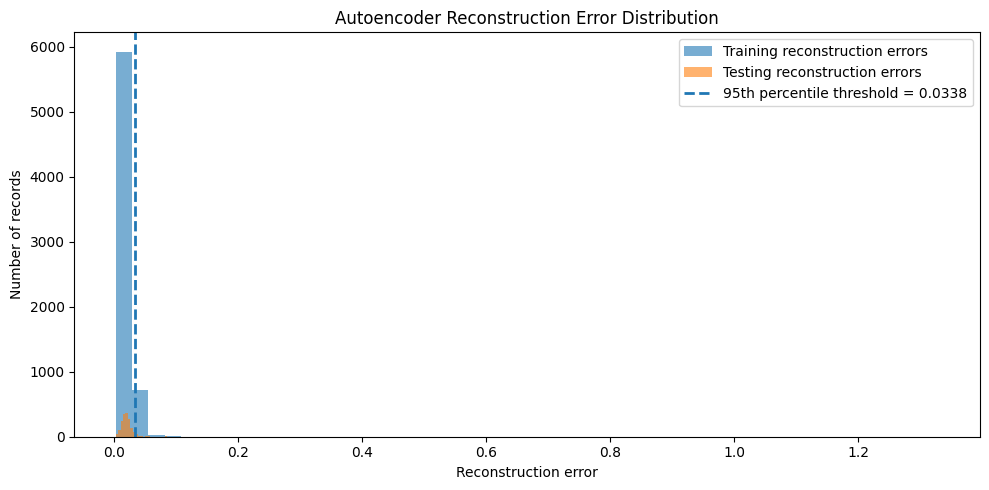

In [138]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 5))

plt.hist(
    train_reconstruction_errors,
    bins=50,
    alpha=0.6,
    label="Training reconstruction errors"
)

plt.hist(
    test_reconstruction_errors,
    bins=50,
    alpha=0.6,
    label="Testing reconstruction errors"
)

plt.axvline(
    anomaly_threshold,
    linestyle="--",
    linewidth=2,
    label=f"95th percentile threshold = {anomaly_threshold:.4f}"
)

plt.xlabel("Reconstruction error")
plt.ylabel("Number of records")
plt.title("Autoencoder Reconstruction Error Distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [139]:
# Validate the anomaly threshold numerically

print(f"Anomaly threshold: {anomaly_threshold:.6f}")

print("\nTraining reconstruction errors:")
print(f"95th percentile: {np.percentile(train_reconstruction_errors, 95):.6f}")
print(f"99th percentile: {np.percentile(train_reconstruction_errors, 99):.6f}")
print(f"Maximum:         {np.max(train_reconstruction_errors):.6f}")

print("\nTesting reconstruction errors:")
print(f"95th percentile: {np.percentile(test_reconstruction_errors, 95):.6f}")
print(f"99th percentile: {np.percentile(test_reconstruction_errors, 99):.6f}")
print(f"Maximum:         {np.max(test_reconstruction_errors):.6f}")

print("\nAnomaly rates:")
print(f"Training: {train_anomalies.mean() * 100:.2f}%")
print(f"Testing:  {test_anomalies.mean() * 100:.2f}%")

Anomaly threshold: 0.033790

Training reconstruction errors:
95th percentile: 0.033790
99th percentile: 0.050391
Maximum:         1.329838

Testing reconstruction errors:
95th percentile: 0.035859
99th percentile: 0.057391
Maximum:         0.200278

Anomaly rates:
Training: 5.00%
Testing:  6.75%


In [144]:
# Compare normal and flagged records numerically

print("TRAINING SET")
print("Normal records:", int((~train_anomalies).sum()))
print("Flagged records:", int(train_anomalies.sum()))

print("\nMean reconstruction error:")
print("Normal:",
      round(train_reconstruction_errors[~train_anomalies].mean(), 6))
print("Flagged:",
      round(train_reconstruction_errors[train_anomalies].mean(), 6))

print("\nTEST SET")
print("Normal records:", int((~test_anomalies).sum()))
print("Flagged records:", int(test_anomalies.sum()))

print("\nMean reconstruction error:")
print("Normal:",
      round(test_reconstruction_errors[~test_anomalies].mean(), 6))
print("Flagged:",
      round(test_reconstruction_errors[test_anomalies].mean(), 6))

TRAINING SET
Normal records: 6360
Flagged records: 335

Mean reconstruction error:
Normal: 0.019002
Flagged: 0.049987

TEST SET
Normal records: 1561
Flagged records: 113

Mean reconstruction error:
Normal: 0.018884
Flagged: 0.047457


In [146]:
import pandas as pd

# Create training anomaly report
train_anomaly_report = pd.DataFrame({
    "original_index": train_idx,
    "dataset_split": "train",
    "reconstruction_error": train_reconstruction_errors,
    "is_anomaly": train_anomalies
})

# Create testing anomaly report
test_anomaly_report = pd.DataFrame({
    "original_index": test_idx,
    "dataset_split": "test",
    "reconstruction_error": test_reconstruction_errors,
    "is_anomaly": test_anomalies
})

# Combine and retain flagged records
anomaly_report = pd.concat(
    [train_anomaly_report, test_anomaly_report],
    ignore_index=True
)

anomaly_report = (
    anomaly_report[anomaly_report["is_anomaly"]]
    .sort_values("reconstruction_error", ascending=False)
    .reset_index(drop=True)
)

print("Potential anomalies:", len(anomaly_report))
display(anomaly_report.head(10))

Potential anomalies: 448


,original_index,dataset_split,reconstruction_error,is_anomaly
0,1539,train,1.329838,True
1,839,train,0.250864,True
2,7063,train,0.247716,True
3,5199,train,0.218123,True
4,574,train,0.205362,True
5,5508,test,0.200278,True
6,490,train,0.126439,True
7,487,test,0.124752,True
8,6626,train,0.108060,True
9,690,train,0.101959,True


In [147]:
# Inspect the 10 highest-error potential anomalies
top_anomalies = anomaly_report.head(10).copy()

# Attach source data using the original row indices
source_records = df_original.loc[
    top_anomalies["original_index"]
].copy()

source_records = source_records.reset_index(drop=True)
top_anomalies = top_anomalies.reset_index(drop=True)

anomaly_review = pd.concat(
    [top_anomalies, source_records],
    axis=1
)

display(anomaly_review)

print("\nOriginal dataset unchanged:",
      df.equals(df_original))

,original_index,dataset_split,reconstruction_error,is_anomaly,Unnamed: 0,it,ft,bt,km,transmission,...,Engine Displacement,Transmission,Year of Manufacture,top_features,Mileage,Engine,Max Power,Torque,Seats.1,Wheel Size
0,1539,train,1.329838,True,58,0,Diesel,Sedan,"55,00,000",Automatic,...,2143 cc,Automatic,2018.0,"['Power Steering', 'Power Windows Front', 'Air...",19.27 kmpl,2143 CC,167.62bhp,400Nm,5.0,16
1,839,train,0.250864,True,839,0,Electric,Hatchback,"20,000",Automatic,...,72 cc,Automatic,2017.0,"['Power Steering', 'Power Windows Front', 'Air...",140 kmpl,72 CC,40bhp,91Nm,4.0,NaN
2,7063,train,0.247716,True,75,0,Petrol,Sedan,"80,000",Manual,...,1817 cc,Manual,NaN,"['Leather Seats', 'Alloy Wheels']",12.8 kmpl,1817 CC,75 PS,130 Nm,5.0,15
3,5199,train,0.218123,True,814,0,Petrol,Hatchback,"50,000",Manual,...,796 cc,Manual,NaN,"['Low Fuel Warning Light', 'Tachometer', 'Fabr...",16.1 kmpl,796 CC,37bhp,59Nm,4.0,12
4,574,train,0.205362,True,574,0,Electric,Hatchback,"20,000",Automatic,...,NaN,Automatic,2017.0,"['Power Steering', 'Power Windows Front', 'Air...",110 kmpl,NaN,25.4bhp,70Nm,4.0,NaN
5,5508,test,0.200278,True,1123,0,Electric,SUV,"20,000",Automatic,...,0 cc,Automatic,2021.0,"['Power Steering', 'Power Windows Front', 'Air...",NaN,0 CC,402.30Bhpbhp,760Nm,5.0,20
6,490,train,0.126439,True,490,0,Petrol,SUV,"10,000",Manual,...,NaN,Manual,NaN,[],NaN,NaN,NaN,NaN,8.0,NaN
7,487,test,0.124752,True,487,0,Petrol,SUV,"10,000",Manual,...,NaN,Manual,NaN,[],NaN,NaN,NaN,NaN,6.0,15
8,6626,train,0.108060,True,758,0,Petrol,Sedan,"1,32,528",Manual,...,1343 cc,Manual,NaN,"['Power Steering', 'Power Windows Front']",13 kmpl,1343 CC,90 bhp,11.3 kgm,5.0,14
9,690,train,0.101959,True,690,0,Petrol,Sedan,"50,000",Manual,...,970 cc,Manual,NaN,"['Power Steering', 'Power Windows Front', 'Air...",15 kmpl,970 CC,NaN,NaN,5.0,13



Original dataset unchanged: True


In [148]:
from pathlib import Path

REPORTS_DIR = Path(
    "/content/drive/MyDrive/ENTRI Folder/ASSIGNMENTS/"
    "Final Main Project/DataLens_AI/reports"
)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

anomaly_report_path = REPORTS_DIR / "cardhekho_anomaly_report.csv"

anomaly_report.to_csv(anomaly_report_path, index=False)

print("Anomaly report saved to:", anomaly_report_path)
print("Total potential anomalies:", len(anomaly_report))
print("Training anomalies:", (anomaly_report["dataset_split"] == "train").sum())
print("Testing anomalies:", (anomaly_report["dataset_split"] == "test").sum())
print("Original dataset unchanged:", df.equals(df_original))

Anomaly report saved to: /content/drive/MyDrive/ENTRI Folder/ASSIGNMENTS/Final Main Project/DataLens_AI/reports/cardhekho_anomaly_report.csv
Total potential anomalies: 448
Training anomalies: 335
Testing anomalies: 113
Original dataset unchanged: True


In [149]:
from pathlib import Path

REPORTS_DIR = Path(
    "/content/drive/MyDrive/ENTRI Folder/ASSIGNMENTS/"
    "Final Main Project/DataLens_AI/reports"
)

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

anomaly_report_path = REPORTS_DIR / "cardhekho_anomaly_report.csv"

anomaly_report.to_csv(anomaly_report_path, index=False)

print("Anomaly report saved to:", anomaly_report_path)
print("Total potential anomalies:", len(anomaly_report))
print(
    "Training anomalies:",
    (anomaly_report["dataset_split"] == "train").sum()
)
print(
    "Testing anomalies:",
    (anomaly_report["dataset_split"] == "test").sum()
)
print("Original dataset unchanged:", df.equals(df_original))

Anomaly report saved to: /content/drive/MyDrive/ENTRI Folder/ASSIGNMENTS/Final Main Project/DataLens_AI/reports/cardhekho_anomaly_report.csv
Total potential anomalies: 448
Training anomalies: 335
Testing anomalies: 113
Original dataset unchanged: True


In [150]:
from pathlib import Path
import json
import joblib

# 1. Create the models directory
MODELS_DIR = Path(
    "/content/drive/MyDrive/ENTRI Folder/ASSIGNMENTS/"
    "Final Main Project/DataLens_AI/models"
)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# 2. Save the trained autoencoder
model_path = MODELS_DIR / "datalens_autoencoder.keras"
autoencoder.save(model_path)

# 3. Save preprocessing objects and feature information
preprocessing_path = MODELS_DIR / "preprocessing_objects.joblib"

joblib.dump(
    {
        "encoder": encoder,
        "scaler": scaler,
        "categorical_features": categorical_features,
        "numeric_features": numeric_features,
        "model_feature_columns": model_features_df.columns.tolist(),
        "encoded_feature_count": int(X_train.shape[1]),
    },
    preprocessing_path,
)

# 4. Save model metadata and anomaly threshold
metadata = {
    "model_name": "DataLens AI Autoencoder",
    "epochs_completed": 50,
    "best_validation_loss": 0.02097141556441784,
    "anomaly_threshold": float(anomaly_threshold),
    "threshold_percentile": 95,
    "training_anomalies": int(train_anomalies.sum()),
    "testing_anomalies": int(test_anomalies.sum()),
    "input_feature_count": int(X_train.shape[1]),
}

metadata_path = MODELS_DIR / "model_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)

# 5. Validate saved files
print("Autoencoder saved:", model_path.exists())
print("Preprocessing objects saved:", preprocessing_path.exists())
print("Metadata saved:", metadata_path.exists())
print("Model input features:", X_train.shape[1])
print("Anomaly threshold:", anomaly_threshold)
print("Original dataset unchanged:", df.equals(df_original))

Autoencoder saved: True
Preprocessing objects saved: True
Metadata saved: True
Model input features: 151
Anomaly threshold: 0.03379005
Original dataset unchanged: True


In [151]:
from pathlib import Path
import joblib
import tensorflow as tf
import json

MODELS_DIR = Path(
    "/content/drive/MyDrive/ENTRI Folder/ASSIGNMENTS/"
    "Final Main Project/DataLens_AI/models"
)

# 1. Load the saved autoencoder
loaded_autoencoder = tf.keras.models.load_model(
    MODELS_DIR / "datalens_autoencoder.keras"
)

# 2. Load the saved preprocessing objects
loaded_preprocessing = joblib.load(
    MODELS_DIR / "preprocessing_objects.joblib"
)

# 3. Load model metadata
with open(
    MODELS_DIR / "model_metadata.json",
    "r",
    encoding="utf-8"
) as file:
    loaded_metadata = json.load(file)

# 4. Validate the loaded artifacts
print("Model loaded:", loaded_autoencoder is not None)
print("Encoder loaded:", "encoder" in loaded_preprocessing)
print("Scaler loaded:", "scaler" in loaded_preprocessing)
print(
    "Loaded model input features:",
    loaded_autoencoder.input_shape[-1]
)
print(
    "Saved anomaly threshold:",
    loaded_metadata["anomaly_threshold"]
)
print("Original dataset unchanged:", df.equals(df_original))

Model loaded: True
Encoder loaded: True
Scaler loaded: True
Loaded model input features: 151
Saved anomaly threshold: 0.03379004821181297
Original dataset unchanged: True


In [152]:
import numpy as np

# 1. Generate reconstructions using the loaded model
X_test_reconstructed = loaded_autoencoder.predict(
    X_test,
    verbose=0
)

# 2. Calculate reconstruction error for each test row
loaded_test_errors = np.mean(
    np.square(X_test - X_test_reconstructed),
    axis=1
)

# 3. Load the saved threshold
saved_threshold = loaded_metadata["anomaly_threshold"]

# 4. Flag potential anomalies
loaded_test_anomalies = loaded_test_errors > saved_threshold

# 5. Validate results
print("Test rows:", len(X_test))
print("Reconstruction errors are finite:", np.isfinite(loaded_test_errors).all())
print("Saved threshold:", saved_threshold)
print("Potential anomalies:", int(loaded_test_anomalies.sum()))
print(
    "Matches previous test predictions:",
    np.array_equal(loaded_test_anomalies, test_anomalies)
)
print("Original dataset unchanged:", df.equals(df_original))

Test rows: 1674
Reconstruction errors are finite: True
Saved threshold: 0.03379004821181297
Potential anomalies: 113
Matches previous test predictions: True
Original dataset unchanged: True
